# Rays and waves in a laser processing head: a diffractive 5 × 5 spot splitter

Fibre lasers drill, scribe and ablate with many spots at once: a
diffractive optical element (DOE) splits the collimated beam into an array
of beams, and a focusing lens puts them side by side onto the workpiece
(parallel processing of solar cells, filters, displays). Such a head mixes
parts that are naturally described by rays with parts that only waves can
describe:

| part | description |
|---|---|
| fibre (single mode, 1070 nm) | wave: the Gaussian mode, its far field gives the ray weights |
| collimator (singlet, f = 30 mm) | rays: refraction, spherical aberration |
| DOE (phase grating, 40 µm period) | **wave**: diffraction orders, efficiencies, zero order, ghosts |
| focusing lens (singlet, f = 100 mm) | rays: off-axis aberrations, spot positions |
| workpiece | **wave**: spot size and peak intensity near the diffraction limit |

This notebook passes the light back and forth with `pyoptics.raywave`, in
the spirit of Wyrowski's field tracing: rays → field in front of the DOE,
the DOE as a thin phase element on the field, the field of every order →
rays through the focusing lens, and the rays → field again at the
workpiece. It sacrifices exactness for illustration: the DOE is a thin
element (no rigorous grating theory), the fields are scalar, and the
diffraction orders are traced independently (they do not overlap at the
workpiece). Notebook 47 tests the conversions themselves against exact
wave propagation.

1. the head: layout, rays → field in front of the DOE,
2. the DOE: design with the iterative Fourier transform algorithm
   (`pyoptics.ifta`), phase levels, etch depth errors,
3. why the DOE needs waves: rays from the field behind the DOE,
4. every order a ray bundle through the focusing lens,
5. back to waves at the workpiece: the spots, rays vs. waves,
6. the spot array with zero order and ghosts, and what an etch depth
   error does to it.

Run time: about 30 seconds.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap

from pyoptics import ifta
from pyoptics.raytrace import System, Surface
from pyoptics.raywave import rays_to_field, straight_rays, field_to_rays, local_spectrum_rays
from pyoptics.analytic_phase import QuadraticPhaseField, propagate
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")
t_start = time.time()

um = 1e-3                    # lengths in mm
WL = 1.07e-3                 # fibre laser
K = 2*np.pi/WL
N_GLASS = 1.5066             # N-BK7 at 1070 nm
W_FIBRE = 0.005              # mode field radius of the fibre (10 µm MFD)
THETA0 = WL/(np.pi*W_FIBRE)  # 1/e² divergence half angle of the mode
PERIOD = 0.040               # DOE period
D_DOE = 20.0                 # collimator to DOE
D_LENS = 30.0                # DOE to focusing lens


def collimator(gap=D_DOE):
    """Plano-convex singlet, f = 30 mm, flat side towards the fibre; image plane = DOE."""
    R = -30*(N_GLASS - 1)
    lens = System([Surface(np.inf, 0.0, semi_diameter=8.0, label="stop"),
                   Surface(np.inf, 3.0, n_after=N_GLASS, semi_diameter=8.0),
                   Surface(R, gap, n_after=1.0, semi_diameter=8.0)], 0, WL,
                  object_distance=30.0, object_height=0.0)
    # fibre in the front focal point
    return System(lens.surfaces, 0, WL, object_distance=lens.paraxial().ffl, object_height=0.0)


def focusing_lens(gap=10.0):
    """Plano-convex singlet, f = 100 mm, curved side towards the beam."""
    R = 100*(N_GLASS - 1)
    return System([Surface(np.inf, 0.0, semi_diameter=12.7, label="stop"),
                   Surface(R, 4.0, n_after=N_GLASS, semi_diameter=12.7),
                   Surface(np.inf, gap, n_after=1.0, semi_diameter=12.7)], 0, WL)


col, foc = collimator(), focusing_lens()
print("fibre {:.2f} mm in front of the collimator, mode divergence {:.1f} mrad".format(
    col.object_distance, THETA0/um))
print("order angle λ/Λ = {:.1f} mrad".format(WL/PERIOD/um))

fibre 28.01 mm in front of the collimator, mode divergence 68.1 mrad
order angle λ/Λ = 26.8 mrad


## 1. The head, and rays → field in front of the DOE

The collimator and the focusing lens are traced separately; between them
sits the DOE, 20 mm behind the collimator and 30 mm in front of the
focusing lens. The focusing lens is drawn with the directions of the
diffraction orders 0, 1 and 2 of the DOE.

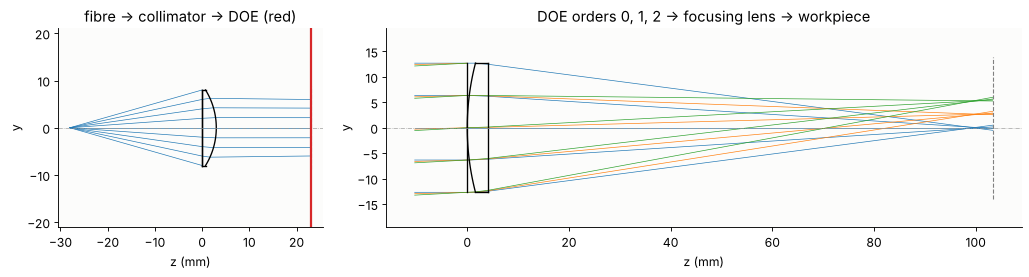

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
col.draw(ax=axes[0], fields=[0.0], n_rays=9, lw=0.6)
axes[0].axvline(col.image_z, color="C3", lw=2)
axes[0].set_title("fibre → collimator → DOE (red)")
angles = [np.arcsin(m*WL/PERIOD) for m in (0, 1, 2)]
f_draw = focusing_lens(foc.at_paraxial_focus().surfaces[-1].thickness + 2)
f_draw.draw(ax=axes[1], fields=angles, n_rays=5, lw=0.6)
axes[1].set_title("DOE orders 0, 1, 2 → focusing lens → workpiece")
for ax in axes:
    ax.set_xlabel("z (mm)")
plt.tight_layout()

The fibre mode is a Gaussian beam with a far field
I(θ) ∝ exp(−2θ²/θ₀²), θ₀ = λ/(πw) = 68 mrad. Rays from the fibre end on a
polar grid of directions get this as their launch irradiance (per unit
slope); `rays_to_field()` collects them into the field in the DOE plane
(the launch positions are the ray slopes). The beam has a 1/e² radius of
2 mm. Its phase carries the spherical aberration of the singlet, about 0.8
waves over the beam: rays have no trouble with that.

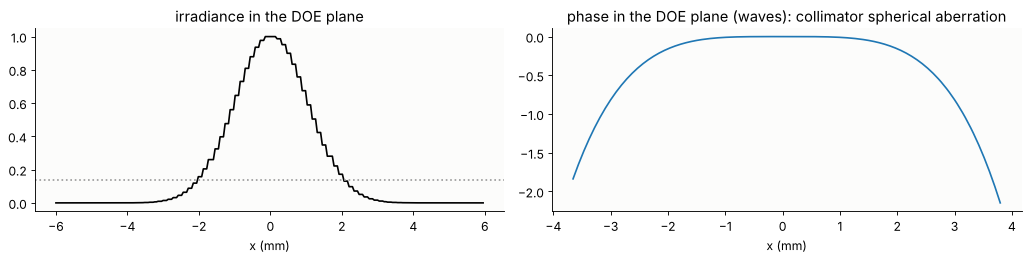

In [3]:
n_r, n_phi = 60, 120
rho, phi = np.linspace(0, 1, n_r), np.linspace(0, 2*np.pi, n_phi + 1)
RHO, PHI = np.meshgrid(rho, phi)
px, py = RHO*np.cos(PHI), RHO*np.sin(PHI)
px[-1], py[-1] = px[0], py[0]
b = col.trace_pupil(0.0, px.ravel(), py.ravel())
shape = px.shape
P = b.points[-1].reshape(shape + (3,))
D = b.directions[-1].reshape(shape + (3,))
S = b.opl[-1].reshape(shape)
slopes = (b.directions[0][:, :2]/b.directions[0][:, 2:]).reshape(shape + (2,))
irr = np.exp(-2*np.sum(slopes**2, -1)/THETA0**2)

x_d = grid1d(-6, 6, 256)
u_doe = rays_to_field(x_d, x_d, P, D, S, WL, launch=slopes, irradiance=irr)
u_doe = u_doe/np.sqrt(np.sum(np.abs(u_doe)**2)*(x_d[1] - x_d[0])**2)  # 1 W
c_d = len(x_d)//2

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
I = np.abs(u_doe[c_d])**2
axes[0].plot(x_d, I/I.max(), "k")
axes[0].axhline(np.exp(-2), color="0.6", ls=":")
axes[0].set_title("irradiance in the DOE plane"), axes[0].set_xlabel("x (mm)")
ph = np.unwrap(np.angle(u_doe[c_d]))
lit = I > 1e-3*I.max()
axes[1].plot(x_d[lit], (ph - ph[c_d])[lit]/(2*np.pi), "C0")
axes[1].set_title("phase in the DOE plane (waves): collimator spherical aberration")
axes[1].set_xlabel("x (mm)")
plt.tight_layout()

## 2. The DOE

A Dammann-type spot splitter is a periodic phase grating whose period is
designed so that 25 orders (m, n = −2 … 2) get equal power. One period,
sampled with 32 × 32 cells, is designed with the Gerchberg-Saxton
algorithm (`ifta.GS`, the Fourier transform of one period gives the
orders), quantized to 16 phase levels (`ifta.digitize_phase()`, four
lithography masks) and refined by adapting the target weights of the
orders until they come out equal (the weighted IFTA, see Ripoll et al.).
Efficiency: power in the 25 orders; non-uniformity: (max − min)/(max + min)
of their powers.

In [4]:
M, NO = 32, 2
c = M//2
target = np.zeros((M, M))
target[c - NO:c + NO + 1, c - NO:c + NO + 1] = 1
signal = target > 0


def orders(phase):
    """Complex amplitudes of the diffraction orders, order (m, n) at [c + n, c + m]."""
    return np.fft.fftshift(np.fft.fft2(np.exp(1j*phase)))/phase.size


def quality(phase):
    E = np.abs(orders(phase))**2
    s = E[signal]
    return s.sum(), (s.max() - s.min())/(s.max() + s.min()), np.max(E[~signal])


rng = np.random.default_rng(0)
weights = target/target.sum()
start = np.sqrt(weights)*np.exp(2j*np.pi*rng.random((M, M)))
for outer in range(15):
    obj = ifta.GS(np.ones((M, M)), weights, 30).iterate(start)[0]
    phase16 = np.angle(ifta.digitize_phase(obj, 16))
    E = np.abs(orders(phase16))**2
    weights[signal] *= np.sqrt(E[signal].mean()/E[signal])
    weights /= weights.sum()
    start = np.sqrt(weights)*np.exp(1j*np.angle(np.fft.fftshift(np.fft.fft2(np.exp(1j*phase16)))))
phase_cont = np.angle(obj)

print("{:22s} {:>10s} {:>16s} {:>14s}".format("", "efficiency", "non-uniformity", "max. ghost"))
for name, ph in (("continuous phase", phase_cont),
                 ("16 levels", phase16),
                 ("8 levels", np.angle(ifta.digitize_phase(obj, 8))),
                 ("4 levels", np.angle(ifta.digitize_phase(obj, 4)))):
    print("{:22s} {:10.1%} {:16.1%} {:14.2%}".format(name, *quality(ph)))

                       efficiency   non-uniformity     max. ghost
continuous phase            93.6%             5.0%          0.25%
16 levels                   92.4%             3.2%          0.23%
8 levels                    89.0%             6.5%          0.25%
4 levels                    78.6%            53.3%          0.32%


The phase of one period and the powers of the orders (log scale). The
design orders hold 3.7 % each; outside them the ghost orders, the price of
the phase-only element and of the quantization.

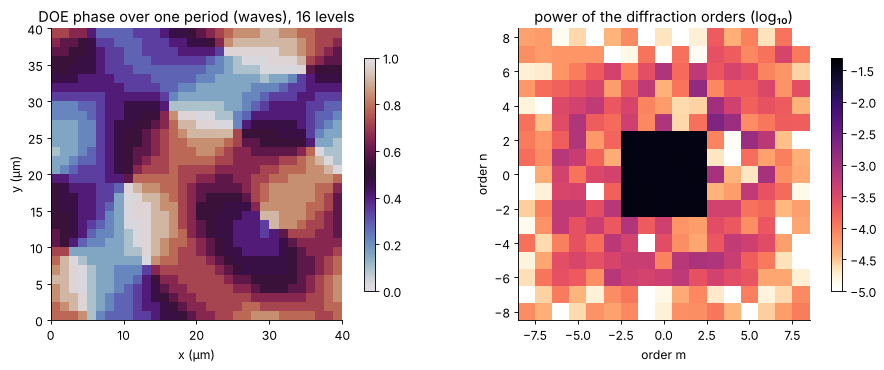

In [5]:
C16 = orders(phase16)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
im = axes[0].imshow(np.mod(phase16, 2*np.pi)/(2*np.pi), cmap="twilight", vmin=0, vmax=1,
                    extent=[0, PERIOD/um, 0, PERIOD/um])
axes[0].set_title("DOE phase over one period (waves), 16 levels")
axes[0].set_xlabel("x (µm)"), axes[0].set_ylabel("y (µm)")
fig.colorbar(im, ax=axes[0], shrink=0.8)
r = 8
E16 = np.abs(C16[c - r:c + r + 1, c - r:c + r + 1])**2
im = axes[1].imshow(np.log10(E16 + 1e-7), cmap=LIGHT, vmin=-5, vmax=np.log10(0.05),
                    extent=[-r - 0.5, r + 0.5, -r - 0.5, r + 0.5])
axes[1].set_title("power of the diffraction orders (log₁₀)")
axes[1].set_xlabel("order m"), axes[1].set_ylabel("order n")
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()

A DOE is etched to a depth that gives 2π at the design wavelength. An
etch depth error ε scales every phase step by (1 + ε). The power in the 25
orders hardly changes, but its distribution does, and most of all the
zero order, the one order that collects the unmodulated light: too
shallow an etch makes it brighter, too deep darker (it is part of the
array here; in designs without a zero order spot it grows quadratically
with ε). The same happens if the element is used at another wavelength
(ε ≈ −Δλ/λ).

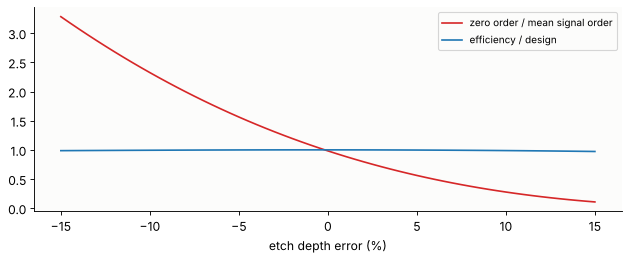

In [6]:
eps = np.linspace(-0.15, 0.15, 61)
zero, eff = [], []
for e in eps:
    E = np.abs(orders(np.mod(phase16, 2*np.pi)*(1 + e)))**2
    zero.append(E[c, c])
    eff.append(E[signal].sum())
zero, eff = np.array(zero), np.array(eff)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(eps*100, zero/(eff/25), "C3", label="zero order / mean signal order")
ax.plot(eps*100, eff/eff[30], "C0", label="efficiency / design")
ax.set_xlabel("etch depth error (%)")
ax.legend(fontsize=9)
plt.tight_layout()

## 3. Why the DOE needs waves

Behind the DOE the field is the incident field times the periodic phase.
Turned into rays along its local phase gradient (`field_to_rays()`), it
gives what geometrical optics gives for a thin plate with an etched
profile: every ray is refracted by the local slope of the profile, and the
directions spread continuously over the whole range of slopes. No trace
of the 25 beams (blue circles). (The patch is sampled with 4 samples per DOE cell and the steps
are rounded over about 1 µm, as etched steps are.) The rays of the DOE are in its
**local spectrum**: `local_spectrum_rays()` cuts the field into windows of
several periods (here 4 periods, 160 µm) and makes a ray of every spectral
component, with the power of that component. Its directions are the
diffraction orders, sin θ = mλ/Λ, and its powers the order efficiencies.
Below a 400 µm wide patch at the centre of the beam, sampled with 0.31 µm.

order (1, 1): local spectrum rays 3.60%, DOE design 3.80%
order (0, 3) (ghost): local spectrum rays 0.175%, DOE design 0.081%


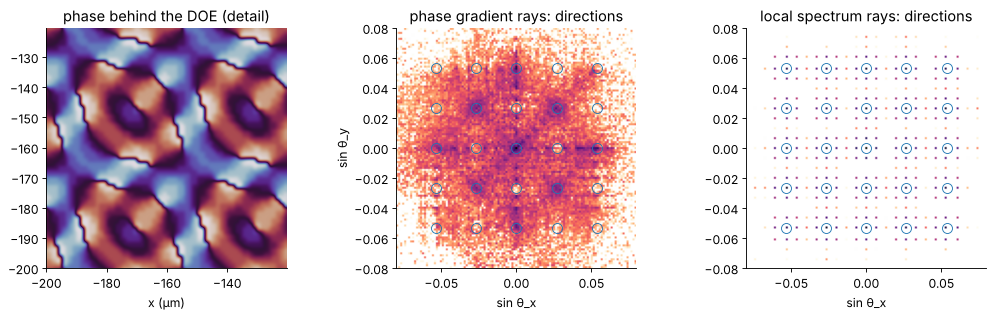

In [7]:
from scipy.ndimage import gaussian_filter

x_p = grid1d(-0.2, 0.2, 1280)
X_p, Y_p = np.meshgrid(x_p, x_p)
cells = np.floor(np.mod(X_p, PERIOD)/PERIOD*M).astype(int), np.floor(np.mod(Y_p, PERIOD)/PERIOD*M).astype(int)
depth = np.mod(phase16, 2*np.pi)[cells[1], cells[0]]       # etch depth in radians
depth = gaussian_filter(depth, 2.0, mode="wrap")            # steps rounded over ~1 µm
u_in = np.exp(-(X_p**2 + Y_p**2)/2.0**2)  # the incident beam, nearly flat on the patch
u_out = u_in*np.exp(1j*depth)

R_grad = field_to_rays(u_out, x_p, x_p, WL)
R_loc = local_spectrum_rays(u_out, x_p, x_p, WL, window=512, step=128, threshold=1e-4, pad=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(np.mod(np.angle(u_out[:256, :256]), 2*np.pi), cmap="twilight",
               extent=[x_p[0]/um, x_p[255]/um]*2)
axes[0].set_title("phase behind the DOE (detail)")
axes[0].set_xlabel("x (µm)")
for ax, R, title in ((axes[1], R_grad, "phase gradient rays"), (axes[2], R_loc, "local spectrum rays")):
    sx, sy = R.directions[:, 0], R.directions[:, 1]
    H, xe, ye = np.histogram2d(sx, sy, bins=121, range=[[-0.08, 0.08]]*2, weights=R.power)
    ax.imshow(np.log10(H.T/H.max() + 1e-6), extent=[-0.08, 0.08, -0.08, 0.08], cmap=LIGHT,
              vmin=-3, vmax=0)
    o = np.arange(-2, 3)*WL/PERIOD
    ax.plot(*np.meshgrid(o, o), "o", mfc="none", mec="C0", ms=9, mew=0.8)
    ax.set_title(title + ": directions")
    ax.set_xlabel("sin θ_x")
axes[1].set_ylabel("sin θ_y")
plt.tight_layout()

order_power = {}
k_order = WL/PERIOD
for m in range(-3, 4):
    for n in range(-3, 4):
        sel = (np.abs(R_loc.directions[:, 0] - m*k_order) < k_order/2) & \
              (np.abs(R_loc.directions[:, 1] - n*k_order) < k_order/2)
        order_power[m, n] = R_loc.power[sel].sum()/R_loc.power.sum()
print("order (1, 1): local spectrum rays {:.2%}, DOE design {:.2%}".format(
    order_power[1, 1], np.abs(C16[c + 1, c + 1])**2))
print("order (0, 3) (ghost): local spectrum rays {:.3%}, DOE design {:.3%}".format(
    order_power[0, 3], np.abs(C16[c + 3, c])**2))

The local spectrum rays carry the order powers of the patch: 3.6 % in the
order (1, 1) against 3.8 % of the ideal design. The difference is real:
the rounded steps of the patch cost some efficiency and feed the ghost
orders (0.18 % instead of 0.08 % in (0, 3)), a well known fabrication
effect. Below, the ideal design is used.

## 4. Every order a ray bundle through the focusing lens

Each order is the incident field, times its complex amplitude c_mn, times
a plane wave with the transverse wave vector (m, n)·2π/Λ. Stored as a
`QuadraticPhaseField` with that carrier, the field of an order is smooth
and `field_to_rays()` differentiates the carrier exactly: a single sheet of
rays, each with direction, power and optical path. With `structured=True`
the rays keep their grid, so that after `System.trace()` they can be
turned into a field again.

First the geometrical picture at the paraxial focus: spot diagrams of the
orders (0, 0), (1, 1) and (2, 2) relative to their centroids, and the
centroid positions against the ideal grid f·tan θ. The orders are equally
spaced in sin θ, not in tan θ: the array is stretched at the corners
(pincushion), by 15 µm at the corner orders.

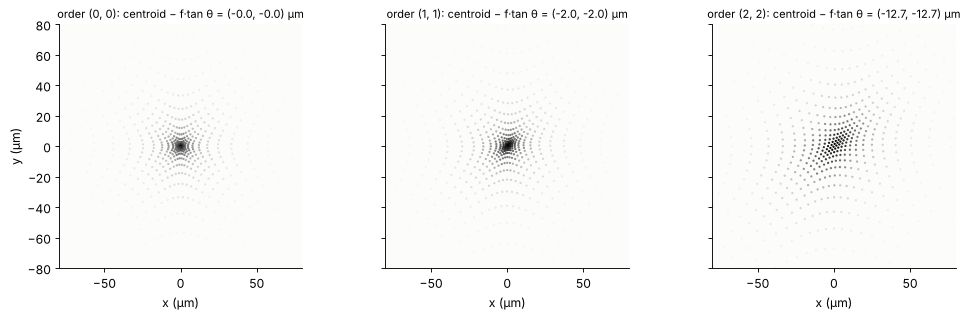

In [8]:
z_doe = -D_LENS                      # DOE plane in the frame of the focusing lens
z_exit = foc.image_z                 # exit plane 10 mm behind the lens
z_parax = foc.at_paraxial_focus().image_z
K_G = 2*np.pi/PERIOD


def order_rays(m, n, C=C16, step=2):
    q = QuadraticPhaseField(C[c + n, c + m]*u_doe, x_d, x_d, WL, beta=(m*K_G, n*K_G))
    R = field_to_rays(q, structured=True, z=z_doe, step=step, threshold=1e-5)
    grid = R.points.shape[:2]
    bundle = foc.trace(R)
    return (R, bundle.points[-1].reshape(grid + (3,)), bundle.directions[-1].reshape(grid + (3,)),
            bundle.opl[-1].reshape(grid))


def centroid(R, Pe, De, Se, z):
    Pz, _ = straight_rays(Pe, De, Se, z)
    ok = np.isfinite(Pz[..., 0])
    w = R.power[ok]
    xy = Pz[..., :2][ok]
    mid = np.average(xy, axis=0, weights=w)
    return mid, xy - mid, w


fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (m, n) in zip(axes, ((0, 0), (1, 1), (2, 2))):
    R, Pe, De, Se = order_rays(m, n, step=4)
    mid, d, w = centroid(R, Pe, De, Se, z_parax)
    ax.scatter(d[:, 0]/um, d[:, 1]/um, s=1, c=w, cmap="Greys", vmin=0, vmax=w.max())
    tx, ty = np.tan(np.arcsin(m*WL/PERIOD)), np.tan(np.arcsin(n*WL/PERIOD))
    ax.set_title("order ({}, {}): centroid − f·tan θ = ({:+.1f}, {:+.1f}) µm".format(
        m, n, (mid[0] - 100*tx)/um, (mid[1] - 100*ty)/um), fontsize=10)
    ax.set_xlim(-80, 80), ax.set_ylim(-80, 80), ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
axes[0].set_ylabel("y (µm)")
plt.tight_layout()

## 5. Back to waves at the workpiece

The geometrical spots are some 30 µm (RMS) across, but the rays carry no
information about the diffraction limit of a 4 mm wide Gaussian beam
focused with f = 100 mm, w₀ = λf/(πw) = 17 µm. Where geometrical blur and
diffraction are of the same size only the wave field gives the spot. For
every order the traced rays in the exit plane 10 mm behind the lens become
a field (`rays_to_field()`, launch: the start points in the DOE plane,
irradiance: the order's |u|²), with its sphere and tilt fitted to the ray
directions and kept analytic (`QuadraticPhaseField`), and
`analytic_phase.propagate()` carries it to a 160 µm window around the
centroid of its rays in the workpiece plane.

Where is the workpiece? The rays say: where the RMS spot is smallest; the
waves: where the peak intensity is highest. For the centre order:

best focus: rays -1.75 mm, waves -1.75 mm from the paraxial focus


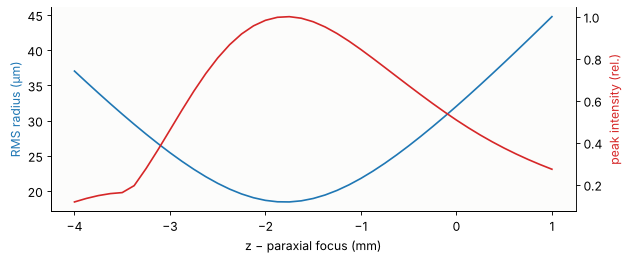

In [9]:
x_e = grid1d(-6, 6, 256)


def fitted(Pe, De):
    """Radius of curvature and tilt (direction slopes at x = 0) of the exit rays."""
    ok = np.isfinite(Pe[..., 0])
    fits = [np.polyfit(Pe[..., a][ok], (De[..., a]/De[..., 2])[ok], 1) for a in (0, 1)]
    return -2/(fits[0][0] + fits[1][0]), (fits[0][1], fits[1][1])


def exit_field(m, n, C=C16):
    R, Pe, De, Se = order_rays(m, n, C)
    u = rays_to_field(x_e, x_e, Pe, De, Se, WL, launch=R.points[..., :2],
                      irradiance=R.power/(x_d[1] - x_d[0])**2/4)
    Rc, tilt = fitted(Pe, De)
    q = QuadraticPhaseField.from_field(u, x_e, x_e, WL, R=-Rc, carrier=(K*tilt[0], K*tilt[1]))
    return q, (R, Pe, De, Se)


def spot(q, z, centre, half=0.08, N=160):
    xo = grid1d(centre[0] - half, centre[0] + half, N)
    yo = grid1d(centre[1] - half, centre[1] + half, N)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        g = propagate(q, z - z_exit, x_out=xo, y_out=yo)
    return xo, yo, g.field()


q00, rays00 = exit_field(0, 0)
dz = np.linspace(-4, 1, 41)
rms, peak = [], []
for d in dz:
    mid, dd, w = centroid(*rays00, z_parax + d)
    rms.append(np.sqrt(np.average(np.sum(dd**2, 1), weights=w)))
    peak.append(np.max(np.abs(spot(q00, z_parax + d, mid, half=0.05, N=100)[2])**2))
rms, peak = np.array(rms), np.array(peak)
z_rays, z_waves = z_parax + dz[np.argmin(rms)], z_parax + dz[np.argmax(peak)]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(dz, rms/um, "C0", label="rays: RMS spot radius (µm)")
ax2 = ax.twinx()
ax2.plot(dz, peak/peak.max(), "C3", label="waves: peak intensity")
ax.set_xlabel("z − paraxial focus (mm)"), ax.set_ylabel("RMS radius (µm)", color="C0")
ax2.set_ylabel("peak intensity (rel.)", color="C3")
ax2.spines["right"].set_visible(True)
plt.tight_layout()
print("best focus: rays {:+.2f} mm, waves {:+.2f} mm from the paraxial focus".format(
    z_rays - z_parax, z_waves - z_parax))

Here the two agree: the focus lies 1.75 mm in front of the paraxial
focus, moved there by the spherical aberration of the two singlets, which
the rays get right. The workpiece goes there. The spots of three orders,
as wave intensity with 1500 rays (drawn with the probability of their
power) on top: the core of the ray spot is smaller than the wave spot,
a few weak rim rays scatter far out. Neither the core nor the RMS radius
(18 µm) tells the size of the spot: diffraction (17 µm for the
aberration free Gaussian beam) and aberrations add up to a 1/e² radius
of 26 µm, from the second moment of the wave intensity. At the corner
order (2, 2), 76 mrad off axis, the rays show the astigmatic cross of the
off-axis singlet, and the wave spot grows by 10 %.

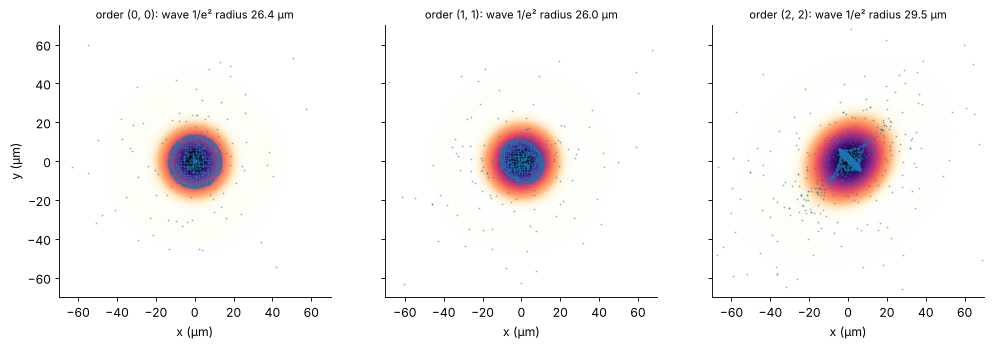

In [10]:
z_work = z_waves
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
spot_stats = []
for ax, (m, n) in zip(axes, ((0, 0), (1, 1), (2, 2))):
    q, rr = exit_field(m, n)
    mid, d, w = centroid(*rr, z_work)
    xo, yo, u = spot(q, z_work, mid)
    I = np.abs(u)**2
    ax.imshow(I/I.max(), extent=[(xo[0] - mid[0])/um, (xo[-1] - mid[0])/um,
                                 (yo[0] - mid[1])/um, (yo[-1] - mid[1])/um], cmap=LIGHT)
    sel = rng.choice(len(w), 1500, p=w/w.sum())
    ax.plot(d[sel, 0]/um, d[sel, 1]/um, ".", color="C0", ms=1.2, alpha=0.5)
    # 1/e² radius from the second moment of the intensity
    Xo, Yo = np.meshgrid(xo - mid[0], yo - mid[1])
    w2 = 2*np.sqrt(np.sum(I*(Xo**2 + Yo**2))/np.sum(I)/2)
    ax.set_title("order ({}, {}): wave 1/e² radius {:.1f} µm".format(m, n, w2/um), fontsize=10)
    ax.set_xlabel("x (µm)")
    ax.set_xlim(-70, 70), ax.set_ylim(-70, 70)
axes[0].set_ylabel("y (µm)")
plt.tight_layout()

## 6. The spot array on the workpiece

All orders up to |m|, |n| = 3 with more than 10⁻⁴ of the power, each
propagated to its own 120 µm window around its centroid; the windows are
shown as tiles in the order of (m, n) (the spots themselves are 2.7 mm
apart), all on one logarithmic scale: the 5 × 5 array and the faint ghost
orders around it. With an etch depth 10 % too shallow, the zero order in
the middle is twice as bright as the others.

8 s
design    : peak intensity of the 25 spots: non-uniformity 15.2%, zero order / mean 1.08
etch −10 %: peak intensity of the 25 spots: non-uniformity 57.5%, zero order / mean 2.54


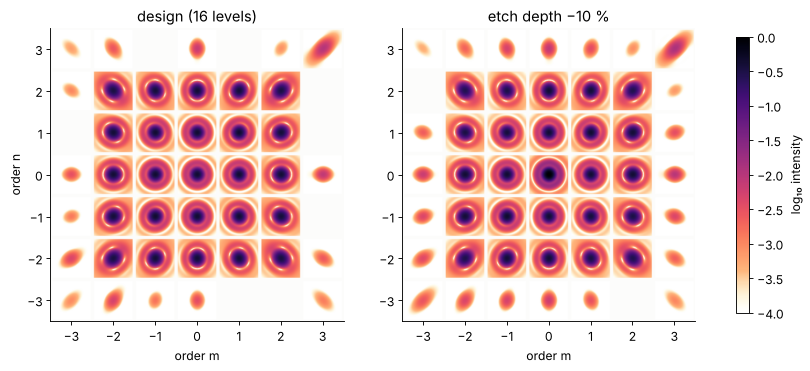

In [11]:
def workpiece(C, threshold=1e-4, half=0.06, N=72, r=3, gap=6):
    """Spots of the orders |m|, |n| <= r as tiles (N x N, separated by gap), and their peaks."""
    T = N + gap
    image = np.full(((2*r + 1)*T, (2*r + 1)*T), np.nan)
    peaks = {}
    for n in range(-r, r + 1):
        for m in range(-r, r + 1):
            if np.abs(C[c + n, c + m])**2 < threshold:
                continue
            q, rr = exit_field(m, n, C)
            mid = centroid(*rr, z_work)[0]
            u = spot(q, z_work, mid, half=half, N=N)[2]
            i, j = (n + r)*T + gap//2, (m + r)*T + gap//2
            image[i:i + N, j:j + N] = np.abs(u)**2
            peaks[m, n] = np.abs(u).max()**2
    return image, peaks


t0 = time.perf_counter()
C_err = orders(np.mod(phase16, 2*np.pi)*0.90)
results = [workpiece(C16), workpiece(C_err)]
print("{:.0f} s".format(time.perf_counter() - t0))

I_max = max(np.nanmax(image) for image, _ in results)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
for ax, (image, peaks), title in zip(axes, results, ("design (16 levels)", "etch depth −10 %")):
    im = ax.imshow(np.log10(image/I_max + 1e-6), extent=[-3.5, 3.5, -3.5, 3.5],
                   cmap=LIGHT, vmin=-4, vmax=0, interpolation="bilinear")
    ax.set_title(title)
    ax.set_xticks(range(-3, 4)), ax.set_yticks(range(-3, 4))
    ax.set_xlabel("order m")
axes[0].set_ylabel("order n")
fig.colorbar(im, ax=axes, shrink=0.7, label="log₁₀ intensity")

for (image, peaks), title in zip(results, ("design", "etch −10 %")):
    sig = np.array([peaks[m, n] for m in range(-2, 3) for n in range(-2, 3)])
    print("{:10s}: peak intensity of the 25 spots: non-uniformity {:.1%}, zero order / mean {:.2f}".format(
        title, (sig.max() - sig.min())/(sig.max() + sig.min()), peaks[0, 0]/sig.mean()))

The power of the 25 orders is uniform to 3 % by design, the peak
intensities on the workpiece much less so: the outer orders pass the
focusing lens at up to 4.3° and are blurred by its off-axis aberrations,
so their peaks drop. That is the ray-optical part of the error budget, the order
powers are the wave-optical part, and the head is specified by both.

## Summary

- A laser processing head with a DOE spot splitter is a hybrid system:
  collimator and focusing lens are ray optics, the DOE and the spots on
  the workpiece are wave optics. `pyoptics.raywave` passes the light
  between the descriptions: rays → field in front of the DOE
  (`rays_to_field()`, with the far field of the fibre mode as ray
  weights), the DOE on the field, every order → rays (`field_to_rays()`
  on a `QuadraticPhaseField` with the order's carrier, `structured=True`)
  through the focusing lens, and the rays → field again behind it,
  propagated to the workpiece with `analytic_phase.propagate()`.
- The DOE, designed with the weighted IFTA at 16 levels, puts 92 % of the
  power into the 25 orders, uniform to 3 %; quantized to fewer
  levels without redesign it loses efficiency and uniformity.
  An etch depth error lifts the zero order quadratically.
- The rays of a DOE are in its local spectrum (`local_spectrum_rays()`):
  discrete directions with the order powers. Its phase gradient (the
  geometrical optics of the etched profile) spreads the light over a
  continuum of directions.
- The rays give the spot positions (the sin θ grid of the orders is
  stretched by the lens, pincushion), the focus shift and the off-axis
  blur, the waves the order powers, the spot size and the peak
  intensities, and with them the uniformity of the process.

In [12]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 18 s


## References

- F. Wyrowski and M. Kuhn, "Introduction to field tracing", J. Mod. Opt. 58, 449-466 (2011).
- H. Dammann and K. Görtler, "High-efficiency in-line multiple imaging by means of multiple phase holograms", Opt. Commun. 3, 312-315 (1971).
- F. Wyrowski and O. Bryngdahl, "Iterative Fourier-transform algorithm applied to computer holography", J. Opt. Soc. Am. A 5, 1058-1065 (1988).
- O. Ripoll, V. Kettunen and H. P. Herzig, "Review of iterative Fourier-transform algorithms for beam shaping applications", Opt. Eng. 43, 2549-2556 (2004).
- D. C. O'Shea, T. J. Suleski, A. D. Kathman and D. W. Prather, *Diffractive Optics: Design, Fabrication, and Test*, SPIE Press (2004).
- B. C. Kress and P. Meyrueis, *Applied Digital Optics*, Wiley (2009).
- J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed., Roberts & Company (2005).
- M. A. Alonso, "Wigner functions in optics: describing beams as ray bundles and pulses as particle ensembles", Adv. Opt. Photon. 3, 272-365 (2011).
- SCHOTT optical glass data sheet N-BK7 (n = 1.5066 at 1070 nm).